In [39]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
from scipy.optimize import least_squares

# Put the Excel files alongside this notebook or change DATA_DIR to their folder.
DATA_DIR = Path(".")
SHEET_NAME = "raw_samples"

# Format: "trial": ("workbook filename", "worksheet name")
# Replace entries as needed. Multiple trials can be in different sheets of one workbook.
TRIAL_SOURCES = {
    "T0": ("TM_Yaxis_neg3_3Distance_Z0.xlsx", SHEET_NAME),
    "T1": ("TM_Yaxis_neg3_3Distance_Z1.xlsx", SHEET_NAME),
    "T2": ("TM_Yaxis_neg3_3Distance_Z2.xlsx", SHEET_NAME),
    "T3": ("TM_Yaxis_neg3_3Distance_Z3.xlsx", SHEET_NAME),  # Replace None with T4's Excel filename
    "T4": ("TM_Yaxis_neg3_3Distance_Z4.xlsx", SHEET_NAME),  # Replace None with T5's Excel filename
    "T5": ("TM_Yaxis_neg3_3Distance_Z5.xlsx", SHEET_NAME),  # Replace None with T5's Excel filename
}

# Hardware position correction: recorded 0..6 mm represents actual -3..+3 mm.
# Applied exactly once during Excel loading (to every trial).
POSITION_OFFSET_MM = -3.0

# Use the same colors for each trial on every plot.
TRIAL_COLORS = {
    "T0": "#2878B5",  # blue
    "T1": "#E17C30",  # orange
    "T2": "#3C9D74",  # green
    "T3": "#C94A55",  # red
    "T4": "#8C65B8",  # purple
    "T5": "#F65FA5",  # pink
}

SHOW_RAW_SAMPLES = False   # Small transparent dots: every sensor reading
SHOW_MEANS = True         # Prominent circle: mean at each distance
SHOW_MIN_MAX_BARS = True # Optional full-range error bars, not standard error
SAVE_PNGS = False        # Set True to also export 6 high-resolution .png plots
OUTPUT_DIR = Path("regression_plots")
EXPORT_CSV = False       # Set True to export regression fit table as CSV

# The fit constrains k to avoid nonphysical numerical explosions, not to impose field polarity.
EXP_K_LIMIT_PER_MM = 3.0

AXES = {"X": "Bx_uT", "Y": "By_uT", "Z": "Bz_uT"}
TRIAL_ORDER = list(TRIAL_SOURCES)


In [40]:
required_columns = {"distance_mm", *AXES.values()}
trial_frames = []
skipped = []

for trial, (file_name, sheet_name) in TRIAL_SOURCES.items():
    if not file_name:
        skipped.append(f"{trial}: no Excel file configured")
        continue

    path = DATA_DIR / file_name
    if not path.is_file():
        skipped.append(f"{trial}: file not found — {path}")
        continue

    try:
        df = pd.read_excel(path, sheet_name=sheet_name)
    except ValueError as exc:
        raise ValueError(f"Cannot read worksheet {sheet_name!r} in {path}: {exc}") from exc

    missing = required_columns - set(df.columns)
    if missing:
        raise ValueError(f"{trial} ({path}) is missing Excel columns: {sorted(missing)}")

    df = df[["distance_mm", *AXES.values()]].copy()
    for col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    df = df.dropna(subset=["distance_mm"])
    # Keep the hardware position for auditing and shift the coordinate
    # used by BOTH plotting and regression to the physical -3..+3 range.
    df["recorded_distance_mm"] = df["distance_mm"]
    df["distance_mm"] = df["recorded_distance_mm"] + POSITION_OFFSET_MM
    df.insert(0, "trial", trial)

    if df.empty:
        skipped.append(f"{trial}: no valid distance measurements in {path}")
    else:
        trial_frames.append(df)
        print(f"Loaded {trial}: {len(df):,} records from {path.name} [{sheet_name}]")

if skipped:
    print("\nUnloaded trials:")
    for reason in skipped:
        print("  -", reason)

if not trial_frames:
    raise FileNotFoundError(
        "No trial data loaded. Place the Excel files in DATA_DIR and edit TRIAL_SOURCES "
        "to match their filenames/sheet names."
    )

raw_data = pd.concat(trial_frames, ignore_index=True)
loaded_trials = set(raw_data["trial"].unique())
print(f"\nReady: {len(raw_data):,} raw readings across {len(loaded_trials)} trial(s).")


Loaded T0: 25,000 records from TM_Yaxis_neg3_3Distance_Z0.xlsx [raw_samples]
Loaded T1: 25,000 records from TM_Yaxis_neg3_3Distance_Z1.xlsx [raw_samples]
Loaded T2: 25,000 records from TM_Yaxis_neg3_3Distance_Z2.xlsx [raw_samples]
Loaded T3: 25,000 records from TM_Yaxis_neg3_3Distance_Z3.xlsx [raw_samples]
Loaded T4: 25,000 records from TM_Yaxis_neg3_3Distance_Z4.xlsx [raw_samples]
Loaded T5: 25,000 records from TM_Yaxis_neg3_3Distance_Z5.xlsx [raw_samples]

Ready: 150,000 raw readings across 6 trial(s).


In [41]:
fit_rows = []


def _r_squared(y, y_pred):
    """Coefficient of determination on *position means*, same for every model."""
    sse = float(np.sum((y - y_pred) ** 2))
    sst = float(np.sum((y - np.mean(y)) ** 2))
    return np.nan if np.isclose(sst, 0) else 1.0 - sse / sst


def _exp_model(p, A, k, C, p0):
    """Offset exponential with a stable, centered position reference."""
    return A * np.exp(np.clip(k * (p - p0), -30.0, 30.0)) + C


def _fit_exponential(x, y):
    """Fit A*exp(k*(p-p0))+C using multiple starts, supporting signed flux.

    Return (predict_function, parameters) or raise ValueError. We normalize y
    internally so tiny/large magnetic units do not impair optimizer stability.
    """
    if len(x) < 4:
        raise ValueError("need at least 4 distinct positions for a reliable exponential fit")

    p0 = float((x.min() + x.max()) / 2)
    offset = float(np.mean(y))
    scale = float(np.ptp(y))
    if scale <= max(1e-12, abs(offset) * 1e-12):
        raise ValueError("flat signal; exponential parameters not identifiable")

    z = (y - offset) / scale
    q = x - p0
    k_max = float(EXP_K_LIMIT_PER_MM)
    # Amplitude/offset bounds prevent huge opposing A and C for nearly linear signals.
    lower = [-30.0, -k_max, -30.0]
    upper = [30.0, k_max, 30.0]
    best = None
    # Both curvature directions, multiple exponential rates and initial signs.
    for k0 in (-1.0, -0.35, -0.1, 0.1, 0.35, 1.0):
        k0 = float(np.clip(k0, -k_max * 0.9, k_max * 0.9))
        shape = np.exp(np.clip(k0 * q, -30, 30))
        # For each fixed k, get best initial A and C by linear least squares.
        design = np.column_stack((shape, np.ones_like(shape)))
        a0, c0 = np.linalg.lstsq(design, z, rcond=None)[0]
        initial = [float(np.clip(a0, -29, 29)), k0, float(np.clip(c0, -29, 29))]
        try:
            fit = least_squares(
                lambda pars: pars[0] * np.exp(np.clip(pars[1] * q, -30, 30)) + pars[2] - z,
                x0=initial, bounds=(lower, upper), max_nfev=1700,
                xtol=1e-10, ftol=1e-10, gtol=1e-10,
            )
        except (ValueError, FloatingPointError):
            continue
        if not fit.success or not np.all(np.isfinite(fit.fun)):
            continue
        error = float(np.sum(fit.fun ** 2))
        if best is None or error < best[0]:
            best = (error, fit.x)

    if best is None:
        raise ValueError("nonlinear least-squares optimization failed")

    a_norm, k, c_norm = map(float, best[1])
    A = a_norm * scale
    C = c_norm * scale + offset
    if abs(k) < 1e-6:
        raise ValueError("exponential rate is effectively zero (flat/unidentifiable fit)")

    def predict(p):
        return _exp_model(np.asarray(p, dtype=float), A, k, C, p0)

    return predict, {"A_exponential": A, "k_exponential_per_mm": k,
                     "C_exponential": C, "p0_mm": p0}


def plot_axis_fit(axis_name, model_type):
    """One X/Y/Z overlay with a separately fitted line for each loaded trial."""
    model_names = {"linear": "Linear", "quadratic": "Quadratic", "exponential": "Exponential"}
    if model_type not in model_names:
        raise ValueError(f"Unknown model type: {model_type}")
    model_name = model_names[model_type]
    flux_col = AXES[axis_name]
    fig, ax = plt.subplots(figsize=(12, 7))
    legend_handles = []

    for trial in TRIAL_ORDER:
        if trial not in loaded_trials:
            continue

        trial_data = raw_data.loc[
            raw_data["trial"] == trial, ["distance_mm", flux_col]
        ].dropna()
        if trial_data.empty:
            continue

        color = TRIAL_COLORS[trial]
        means = (
            trial_data.groupby("distance_mm")[flux_col]
            .agg(["mean", "min", "max", "count"])
            .reset_index()
            .sort_values("distance_mm")
        )
        x = means["distance_mm"].to_numpy(dtype=float)
        y = means["mean"].to_numpy(dtype=float)

        if SHOW_RAW_SAMPLES:
            ax.scatter(
                trial_data["distance_mm"], trial_data[flux_col],
                color=color, alpha=0.13, s=10, linewidths=0,
                rasterized=True, zorder=1,
            )

        if SHOW_MIN_MAX_BARS:
            # The full min-max range is NOT standard error.
            yerr = [y - means["min"].to_numpy(), means["max"].to_numpy() - y]
            ax.errorbar(
                x, y, yerr=yerr, fmt="o", ms=5, color=color,
                capsize=2, elinewidth=0.9, alpha=0.7, zorder=3,
            )
        elif SHOW_MEANS:
            ax.scatter(x, y, color=color, s=49, marker="o",
                       edgecolors="white", linewidths=0.7, zorder=4)

        min_count = 4 if model_type == "exponential" else (2 if model_type == "linear" else 3)
        if len(x) < min_count:
            legend_label = f"{trial} (need ≥{min_count} positions for {model_name.lower()} fit)"
        else:
            try:
                coefficients = {"a_quadratic": np.nan, "b_linear": np.nan,
                                "c_intercept": np.nan, "A_exponential": np.nan,
                                "k_exponential_per_mm": np.nan,
                                "C_exponential": np.nan, "p0_mm": np.nan}
                if model_type in ("linear", "quadratic"):
                    degree = 1 if model_type == "linear" else 2
                    poly_coeffs = np.polyfit(x, y, degree)
                    predict = lambda p, co=poly_coeffs: np.polyval(co, p)
                    coefficients.update({
                        "a_quadratic": poly_coeffs[0] if degree == 2 else 0.0,
                        "b_linear": poly_coeffs[-2],
                        "c_intercept": poly_coeffs[-1],
                    })
                else:
                    predict, exp_coeffs = _fit_exponential(x, y)
                    coefficients.update(exp_coeffs)

                fitted_at_means = predict(x)
                if not np.all(np.isfinite(fitted_at_means)):
                    raise ValueError("fit generated nonfinite values")
                r2 = _r_squared(y, fitted_at_means)
                rmse = float(np.sqrt(np.mean((y - fitted_at_means) ** 2)))
                x_smooth = np.linspace(x.min(), x.max(), 300)
                ax.plot(x_smooth, predict(x_smooth), color=color, lw=2.3, zorder=2)

                legend_label = f"{trial} (R²={r2:.3f})" if np.isfinite(r2) else f"{trial} (R²=N/A)"
                fit_rows.append({
                    "axis": axis_name, "trial": trial, "regression": model_name,
                    "raw_readings": len(trial_data), "distinct_distances": len(x),
                    "R2": r2, "RMSE_uT": rmse, **coefficients,
                })
            except (ValueError, FloatingPointError, np.linalg.LinAlgError) as exc:
                legend_label = f"{trial} (fit unavailable: {exc})"
                print(f"{axis_name} {trial} {model_name}: {exc}")

        legend_handles.append(Line2D(
            [0], [0], color=color, lw=2.3, marker="o", markersize=6,
            label=legend_label,
        ))

    ax.set_title(f"{axis_name} magnetic flux vs. relative position — {model_name} regression", fontsize=15)
    ax.set_xlabel("Relative position (mm; recorded position − 3)")
    ax.set_ylabel(f"B{axis_name.lower()} (µT)")
    ax.grid(alpha=0.25)
    ax.set_axisbelow(True)
    ax.legend(handles=legend_handles, title="Trials and model quality", loc="best")
    fig.tight_layout()
    return fig, ax


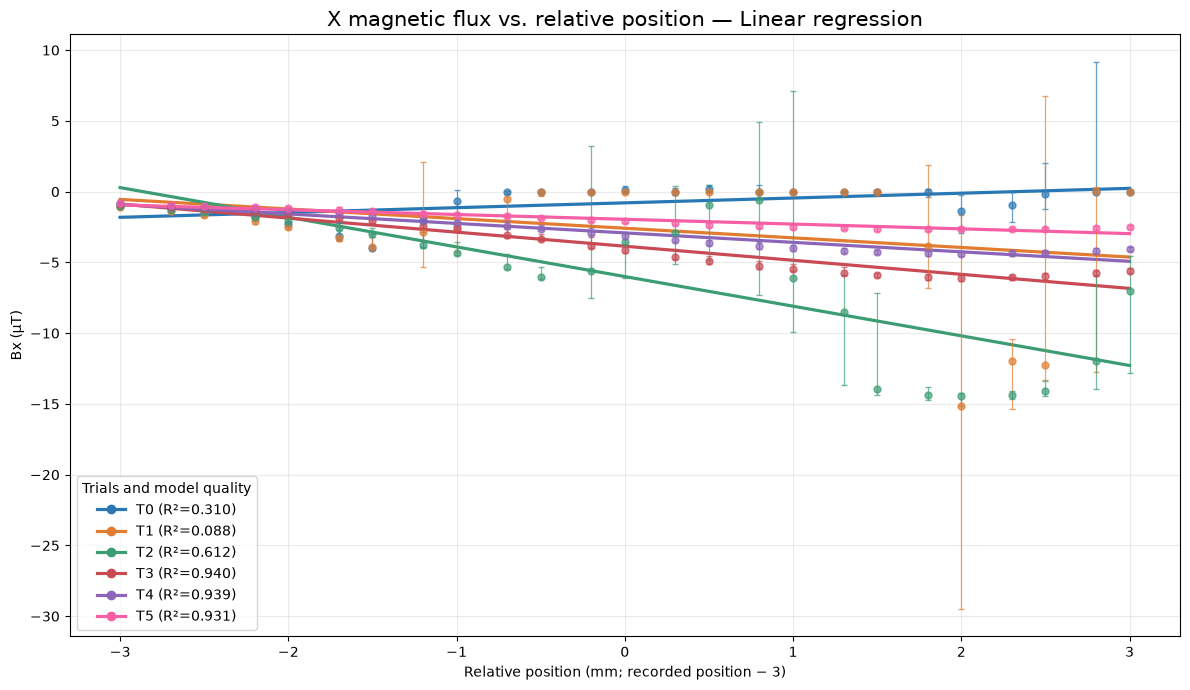

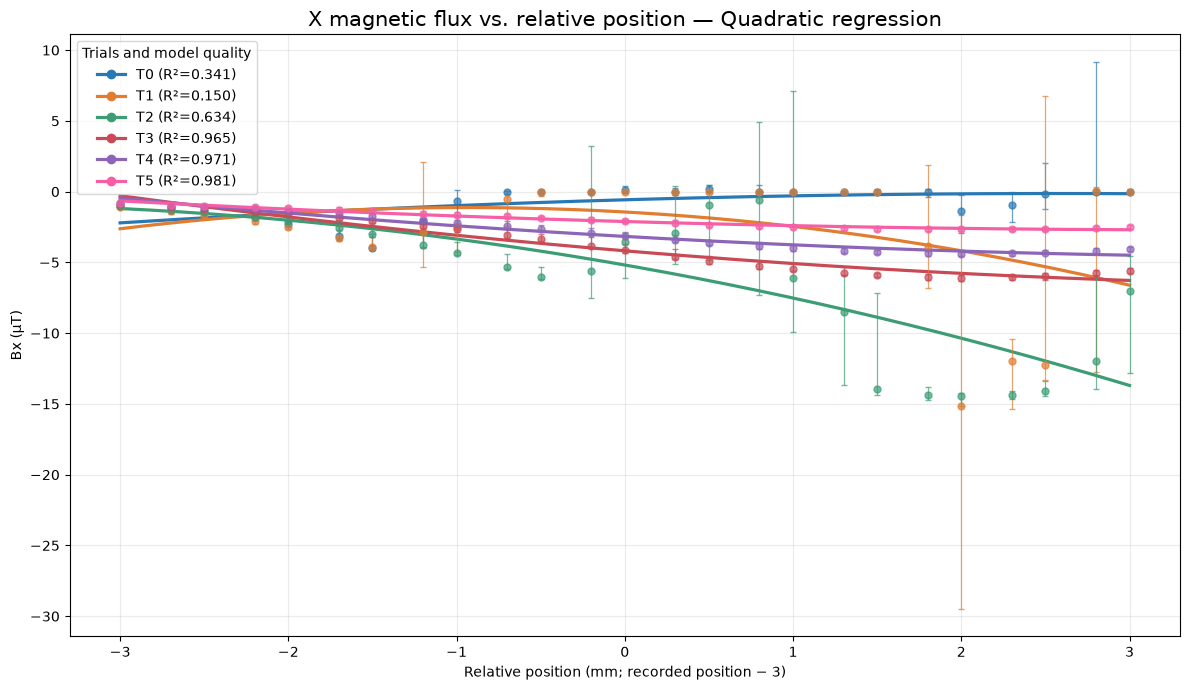

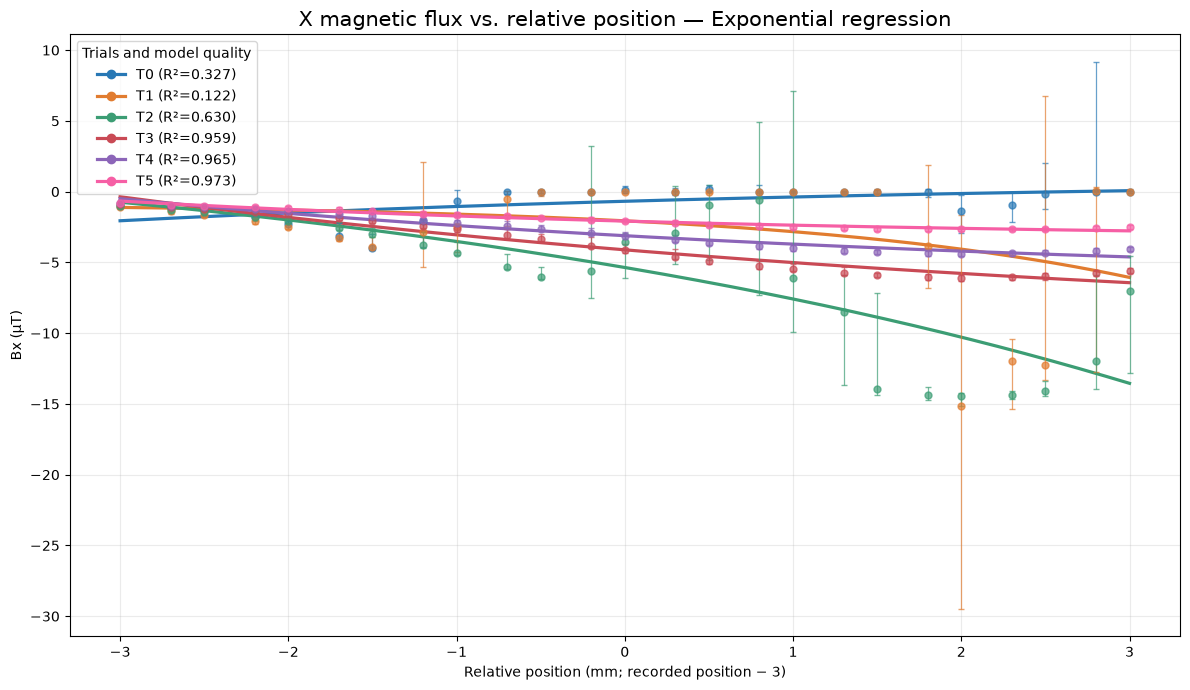

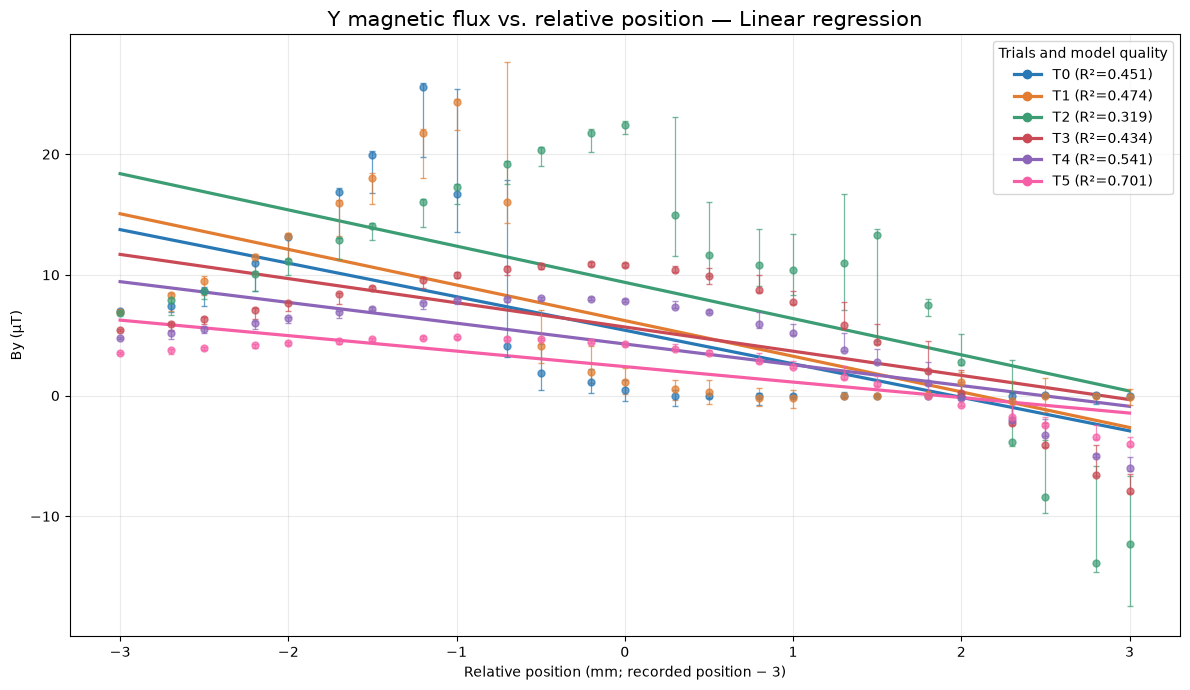

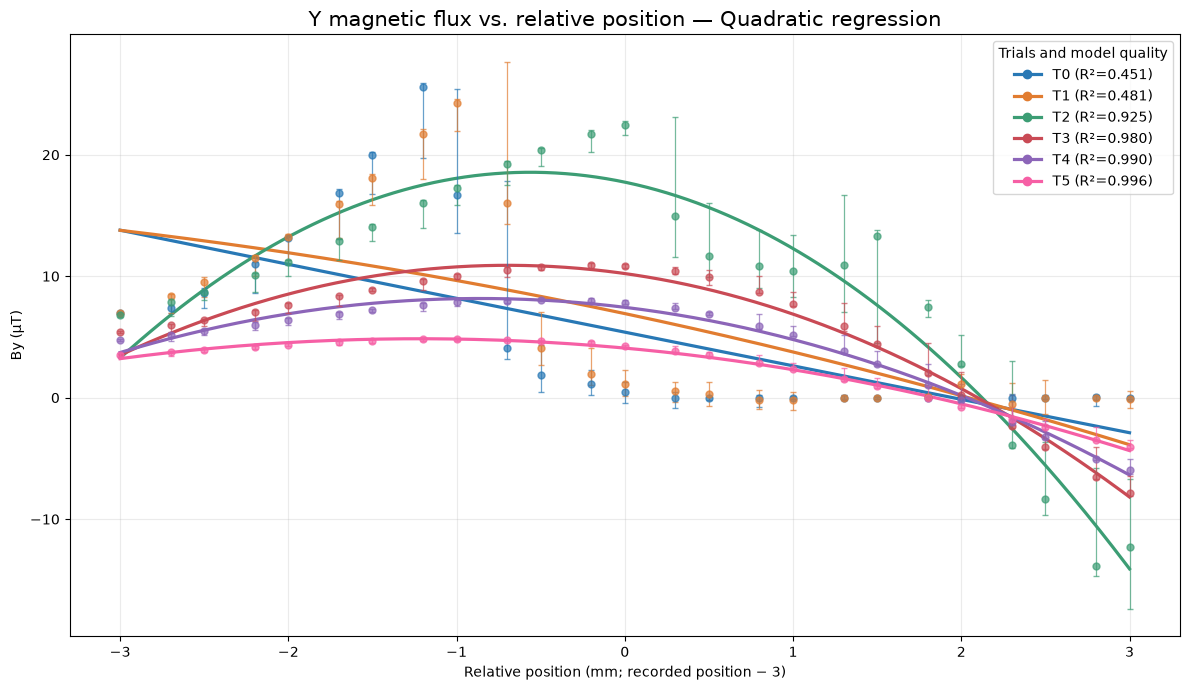

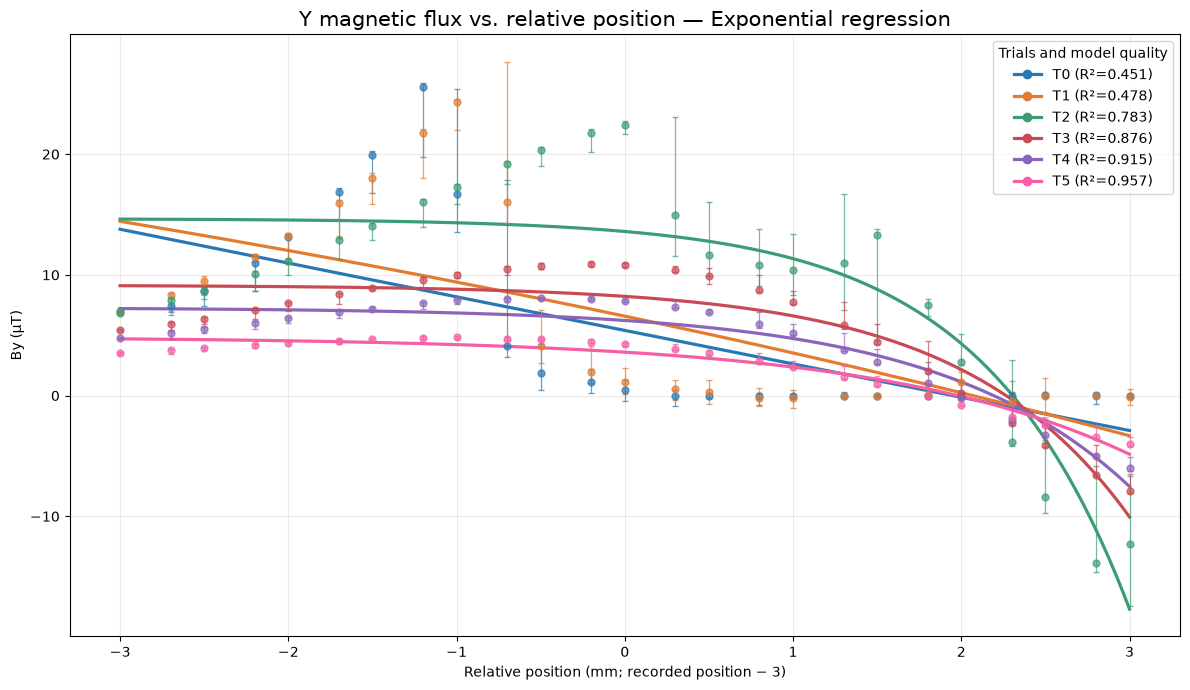

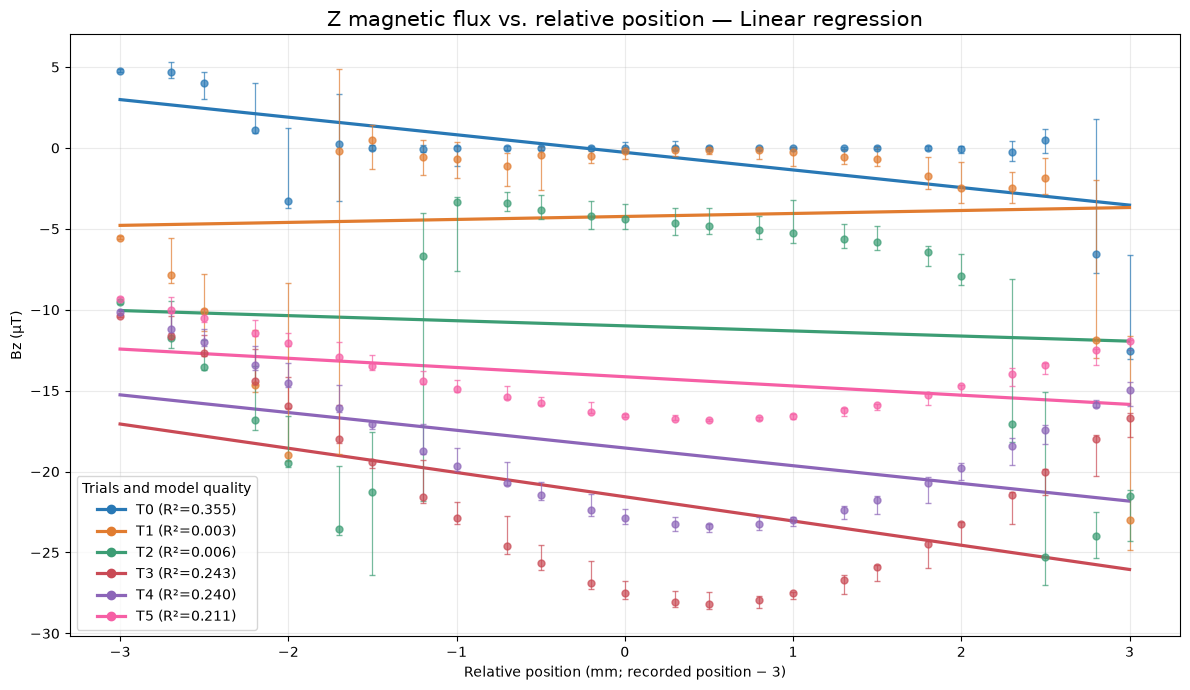

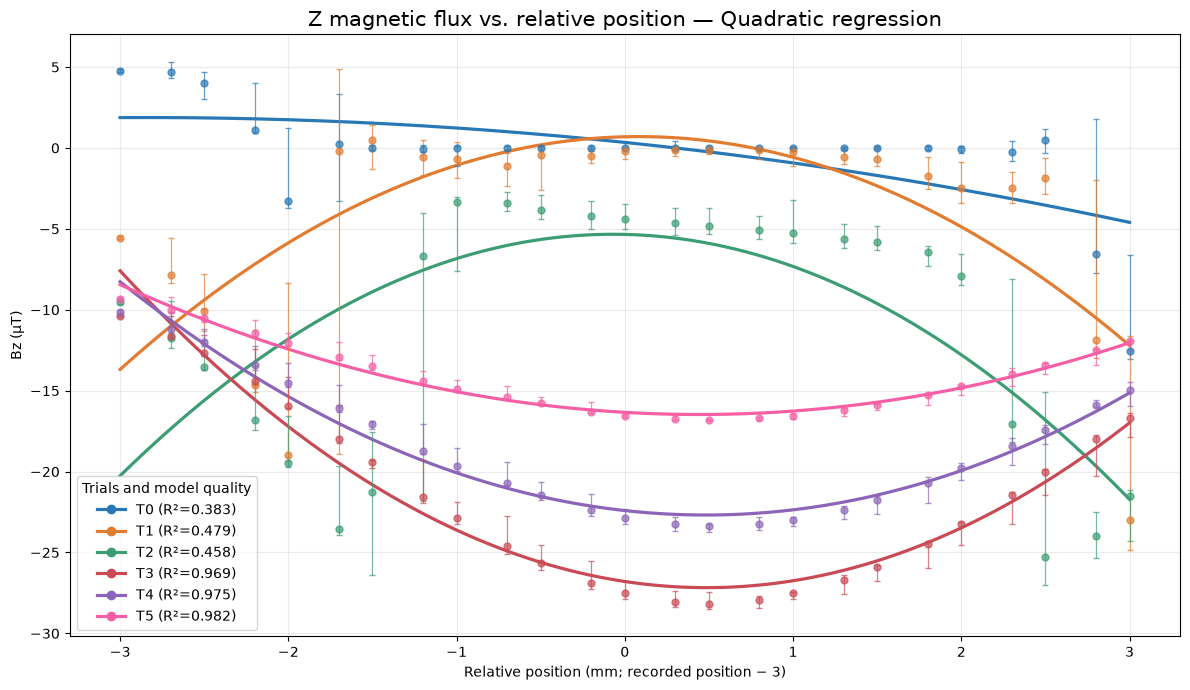

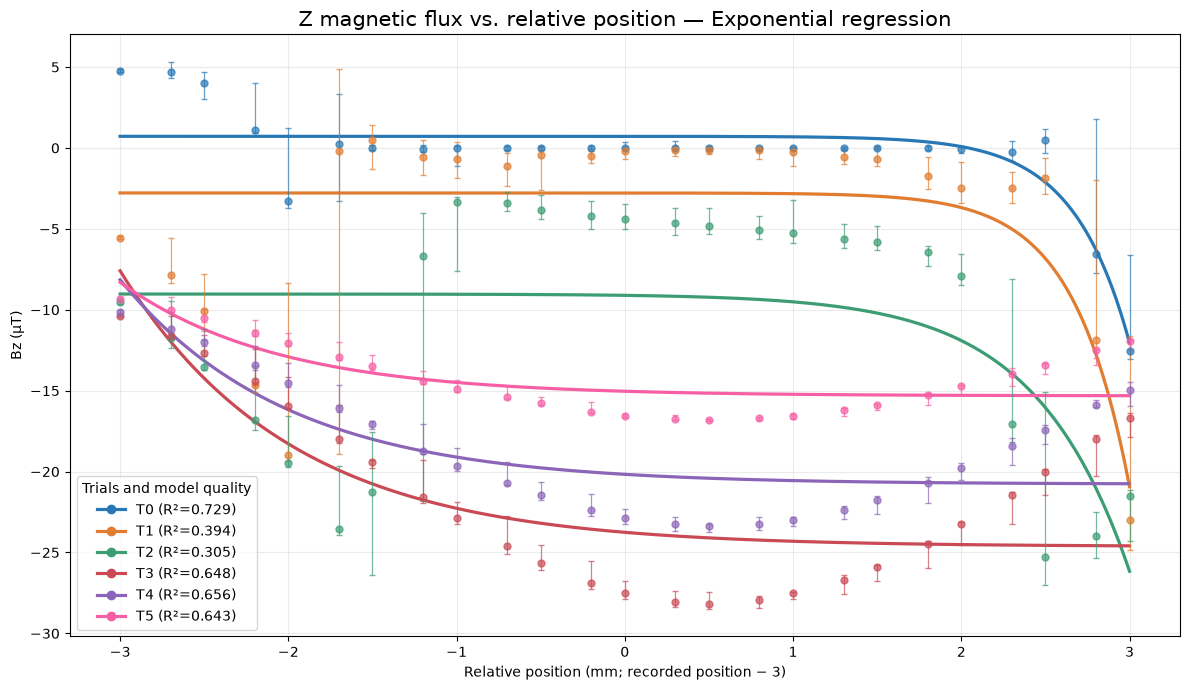

Regression comparison (R² and RMSE evaluated on position means):


R2                        RMSE_uT                   
regression Exponential   Linear Quadratic Exponential   Linear Quadratic
axis trial                                                              
X    T0        0.32693  0.31042   0.34112     0.90553  0.91656   0.89593
     T1        0.12194  0.08817   0.14991     3.86486  3.93848   3.80280
     T2        0.63015  0.61162   0.63441     2.93672  3.00938   2.91975
     T3        0.95947  0.93988   0.96451     0.37191  0.45296   0.34803
     T4        0.96528  0.93938   0.97131     0.23201  0.30654   0.21087
     T5        0.97250  0.93057   0.98085     0.10467  0.16632   0.08734
Y    T0        0.45110  0.45109   0.45110     5.52669  5.52671   5.52667
     T1        0.47784  0.47434   0.48108     5.58284  5.60156   5.56548
     T2        0.78284  0.31851   0.92463     4.46843  7.91579   2.63246
     T3        0.87627  0.43448   0.97986     1.92867  4.12337   0.77819
     T4        0.91453  0.54144   0.99019     1.23304  2.85615   0.41766
     T5        0.95721  0.70145   0.99646     0.57142  1.50944   0.16441
Z    T0        0.72919  0.35501   0.38291     1.71159  2.64147   2.58371
     T1        0.39357  0.00271   0.47941     4.95803  6.35814   4.59377
     T2        0.30451  0.00575   0.45806     6.25446  7.47811   5.52103
     T3        0.64805  0.24268   0.96940     3.25320  4.77209   0.95921
     T4        0.65578  0.24025   0.97543     2.36227  3.50951   0.63112
     T5        0.64275  0.21076   0.98178     1.33788  1.98854   0.30211

Full fitted model coefficients:


,axis,trial,regression,raw_readings,distinct_distances,R2,RMSE_uT,a_quadratic,b_linear,c_intercept,A_exponential,k_exponential_per_mm,C_exponential,p0_mm
0,X,T0,Linear,25000,25,0.3104,0.916561,0.000000,0.341085,-0.792914,NaN,NaN,NaN,NaN
1,X,T1,Linear,25000,25,0.0882,3.938482,0.000000,-0.679272,-2.586388,NaN,NaN,NaN,NaN
2,X,T2,Linear,25000,25,0.6116,3.009385,0.000000,-2.094633,-5.999999,NaN,NaN,NaN,NaN
3,X,T3,Linear,25000,25,0.9399,0.452958,0.000000,-0.993341,-3.857250,NaN,NaN,NaN,NaN
4,X,T4,Linear,25000,25,0.9394,0.306539,0.000000,-0.669294,-2.915573,NaN,NaN,NaN,NaN
5,X,T5,Linear,25000,25,0.9306,0.166315,0.000000,-0.337716,-1.954625,NaN,NaN,NaN,NaN
6,X,T0,Quadratic,25000,25,0.3411,0.895926,-0.066657,0.343884,-0.576265,NaN,NaN,NaN,NaN
7,X,T1,Quadratic,25000,25,0.1499,3.802799,-0.353251,-0.664435,-1.438256,NaN,NaN,NaN,NaN
8,X,T2,Quadratic,25000,25,0.6344,2.919752,-0.251271,-2.084079,-5.183320,NaN,NaN,NaN,NaN
9,X,T3,Quadratic,25000,25,0.9645,0.348030,0.099925,-0.997538,-4.182024,NaN,NaN,NaN,NaN


In [42]:
if SAVE_PNGS or EXPORT_CSV:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_TYPES = ("linear", "quadratic", "exponential")
for axis_name in AXES:
    figs_and_axes = {model: plot_axis_fit(axis_name, model) for model in MODEL_TYPES}

    # Align all three model plots for each axis (not just linear vs quadratic).
    x_lo = min(ax.get_xlim()[0] for fig, ax in figs_and_axes.values())
    x_hi = max(ax.get_xlim()[1] for fig, ax in figs_and_axes.values())
    y_lo = min(ax.get_ylim()[0] for fig, ax in figs_and_axes.values())
    y_hi = max(ax.get_ylim()[1] for fig, ax in figs_and_axes.values())
    for model_type, (fig, ax) in figs_and_axes.items():
        ax.set_xlim(x_lo, x_hi)
        ax.set_ylim(y_lo, y_hi)
        if SAVE_PNGS:
            fig.savefig(OUTPUT_DIR / f"B{axis_name.lower()}_{model_type}.png", dpi=220, bbox_inches="tight")
        plt.show()

fit_results = pd.DataFrame(fit_rows)
if fit_results.empty:
    print("No valid fits available. Verify your data and trial mappings.")
else:
    print("Regression comparison (R² and RMSE evaluated on position means):")
    score_table = fit_results.pivot_table(
        index=["axis", "trial"], columns="regression", values=["R2", "RMSE_uT"]
    )
    display(score_table.round(5))

    print("Full fitted model coefficients:")
    display(fit_results.round({
        "R2": 4, "RMSE_uT": 6, "a_quadratic": 6, "b_linear": 6,
        "c_intercept": 6, "A_exponential": 6, "k_exponential_per_mm": 6,
        "C_exponential": 6, "p0_mm": 3,
    }))

    if EXPORT_CSV:
        csv_file = OUTPUT_DIR / "fit_coefficients_and_scores.csv"
        fit_results.to_csv(csv_file, index=False)
        print(f"Saved model comparison to {csv_file}")
